## VINDPROGNOSE BERGEN
Hvor mye strøm kan en vindturbin ved Bergen produsere, og kan vi forutsi produksjonen fra værdata?

In [21]:
import requests

import pandas as pd

import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

## Hente data

Vi henter vindhastighet time for time i 10 og 120 meters høyde fra Open-Meteo sitt historiske arkiv.

In [22]:
def hent_vinddata(start, slutt, lat=60.39, lon=5.32):
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": lat,
        "longitude": lon,
        "hourly": "wind_speed_10m,wind_speed_120m",
        "start_date": start,
        "end_date": slutt,
        "wind_speed_unit": "ms",
        "timezone": "Europe/Oslo"
    }

    svar = requests.get(url, params=params)
    if svar.status_code != 200:
        raise Exception(f"Feil fra API-et: {svar.status_code} {svar.text}")

    data = svar.json()
    
    df = pd.DataFrame(data["hourly"])
    df["time"] = pd.to_datetime(df["time"])
    return df

In [23]:
df = hent_vinddata("2025-01-01", "2025-12-31")
print(df.shape)
print(df.isna().sum())

(8760, 3)
time               0
wind_speed_10m     0
wind_speed_120m    0
dtype: int64


Datasettet har 8760 timer (hele 2025) og ingen manglende verdier

## Utforske data

In [24]:
df["maaned"] = df["time"].dt.month
df

,time,wind_speed_10m,wind_speed_120m,maaned
0,2025-01-01 00:00:00,2.71,5.02,1
1,2025-01-01 01:00:00,2.52,4.74,1
2,2025-01-01 02:00:00,3.34,6.09,1
3,2025-01-01 03:00:00,3.32,6.25,1
4,2025-01-01 04:00:00,2.29,4.39,1
...,...,...,...,...
8755,2025-12-31 19:00:00,3.85,7.42,12
8756,2025-12-31 20:00:00,3.64,8.02,12
8757,2025-12-31 21:00:00,6.10,10.97,12
8758,2025-12-31 22:00:00,3.32,7.01,12


In [25]:
per_maaned = df.groupby("maaned")["wind_speed_120m"].mean()
per_maaned.sort_values()

maaned
7     3.487003
4     4.635083
9     4.800125
6     5.912653
8     5.962191
1     6.007863
5     6.057608
3     6.187258
10    6.239140
11    6.370417
2     6.412619
12    6.571116
Name: wind_speed_120m, dtype: float64

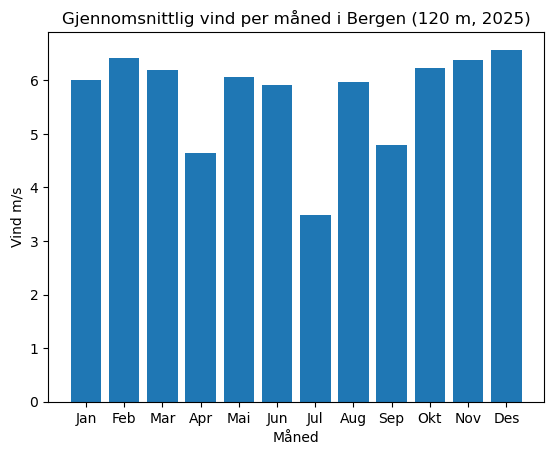

In [26]:
plt.bar(per_maaned.index, per_maaned.values)
plt.title("Gjennomsnittlig vind per måned i Bergen (120 m, 2025)")
plt.xlabel("Måned")
plt.ylabel("Vind m/s")
plt.xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Des"])
plt.savefig("grafer/vind_per_maaned.png", bbox_inches="tight")
plt.show()

Grafen viser oss gjennomsnittlig vind(m/s) per måned i Bergen for året 2025, på 120m høyde.

Vi ser at det blåser minst i månedene: April, Juli og September. Det blåser mest i månedene: Februar, November og Desember.

Vinteren er generelt mer vindfull enn sommeren: Desember har nesten dobbelt så høy snittvind som juli. April og september skiller seg ut med lav vind, men siden dette bare er ett år, kan det være tilfeldig variasjon.

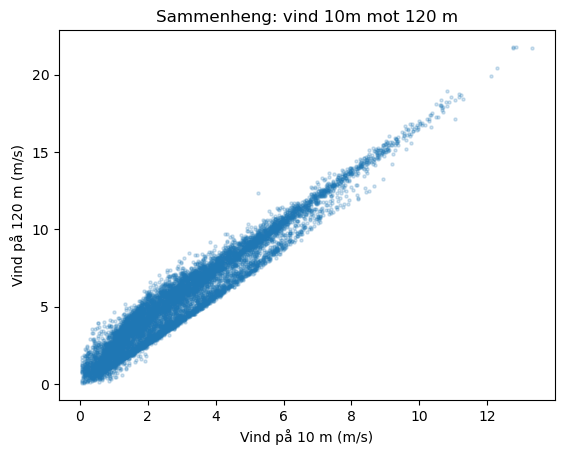

In [27]:
plt.scatter(df["wind_speed_10m"], df["wind_speed_120m"], alpha=0.2, s=5)
plt.title("Sammenheng: vind 10m mot 120 m")
plt.xlabel("Vind på 10 m (m/s)")
plt.ylabel("Vind på 120 m (m/s)")
plt.savefig("grafer/sammenheng_10m_120m.png", bbox_inches="tight")
plt.show()

Grafen viser at det nesten alltid blåser mer i 120 meter enn i 10 meter, og at sammenhengen er tilnærmet lineær: Vinden i 120 meter er rundt 1,6 ganger sterkere. Ved lav vind er spredningen størst, så der er sammenhengen mindre forutsigbar. Det tyder på at en lineær modell kan fungere godt, men med størst usikkerhet ved lave vindhastigheter.

## Fra vind til produksjon

Vi bruker en tenkt 4 MW-turbin som starter ved 3 m/s, når full effekt ved 12 m/s, og stopper ved 25 m/s. Kurven er forenklet.

In [28]:
def produksjon(vind):
    """Regner om vindhastighet (m/s) til produksjon (MW) for en 4 MW-turbin."""
    if vind < 3:
        return 0
    elif vind < 12:
        return 4 * ((vind - 3) / 9) ** 3
    elif vind < 25:
        return 4
    else:
        return 0

In [29]:
df["produksjon_mw"] = df["wind_speed_120m"].apply(produksjon)

In [30]:
vindverdier = [v / 10 for v in range(0, 301)]       # 0.0, 0.1, ... 30.0 m/s
produksjoner = [produksjon(v) for v in vindverdier]

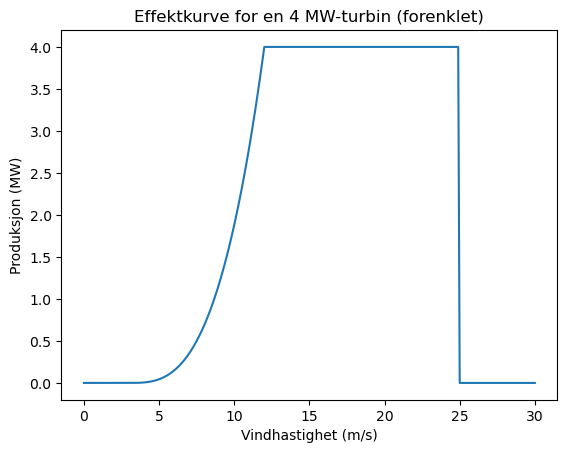

In [31]:
plt.plot(vindverdier, produksjoner)
plt.title("Effektkurve for en 4 MW-turbin (forenklet)")
plt.xlabel("Vindhastighet (m/s)")
plt.ylabel("Produksjon (MW)")
plt.xticks(range(0, 31, 5))
plt.savefig("grafer/effektkurve.png", bbox_inches="tight")
plt.show()

In [32]:
total = df["produksjon_mw"].sum()
maks_mulig = 4 * len(df)
print(f"Total produksjon 2025: {total:.0f} MWh")
print(f"Kapasitetsfaktor: {total / maks_mulig:.1%}")

Total produksjon 2025: 5137 MWh
Kapasitetsfaktor: 14.7%


Turbinen ville produsert rundt 5 140 MWh i 2025, som gir en kapasitetsfaktor på 14,7 %. Det er lavt sammenlignet med typiske vindparker på land. Én grunn er at sommermånedene har lite vind, som vist i grafen over vind per måned. En annen er at koordinatene er Bergen sentrum, et skjermet sted. Ekte vindparker plasseres der det blåser mer, for eksempel ved kysten eller på fjellet.

## Modell: vind i navhøyde fra bakkevind

Det finnes ofte bare målinger nær bakken, mens det er vinden i navhøyde som avgjør produksjonen. Spredningsplottet viste en nesten lineær sammenheng, så en lineær regresjon er et naturlig første valg.

In [ ]:
X = df[["wind_speed_10m"]]
y = df["wind_speed_120m"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

modell = LinearRegression()
modell.fit(X_train, y_train)

prediksjon = modell.predict(X_test)
print(mean_absolute_error(y_test, prediksjon))
print(mean_absolute_error(y_test, X_test["wind_speed_10m"]))

0.7036708605401207
2.926775114155251


In [39]:
print(modell.coef_)       # a: stigningstallet
print(modell.intercept_)  # b: konstantleddet

[1.5835019]
0.6202806679383537


In [47]:
df.loc[X_test.index, "prediksjon"] = prediksjon
test = df.loc[X_test.index]   # hele testperioden
utsnitt = test.iloc[:336]     # de første to ukene

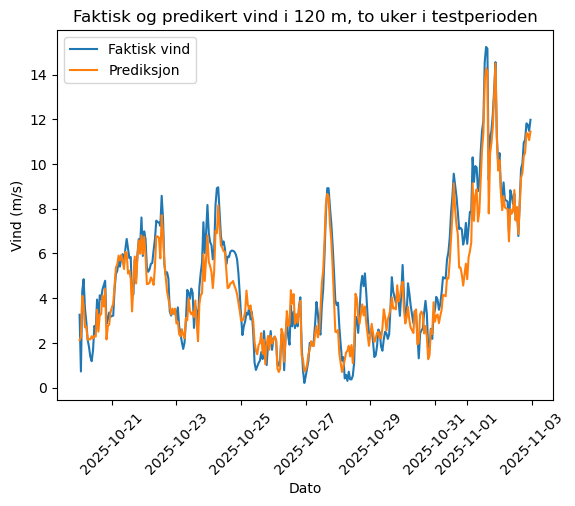

In [51]:
plt.plot(utsnitt["time"], utsnitt["wind_speed_120m"], label="Faktisk vind")
plt.plot(utsnitt["time"], utsnitt["prediksjon"], label="Prediksjon")
plt.title("Faktisk og predikert vind i 120 m, to uker i testperioden")
plt.xlabel("Dato")
plt.ylabel("Vind (m/s)")
plt.legend()
plt.xticks(rotation=45)
plt.savefig("grafer/modell_utsnitt.png", bbox_inches="tight")
plt.show()

In [52]:
print(f"MAE modell: {mean_absolute_error(y_test, prediksjon):.2f} m/s")
print(f"MAE enkel gjetning: {mean_absolute_error(y_test, X_test['wind_speed_10m']):.2f} m/s")
print(f"a = {modell.coef_[0]:.2f}, b = {modell.intercept_:.2f} m/s")

MAE modell: 0.70 m/s
MAE enkel gjetning: 2.93 m/s
a = 1.58, b = 0.62 m/s


Modellen bommer i snitt med 0,70 m/s på testperioden (20. oktober–31. desember 2025), mot 2,93 m/s for en enkel gjetning der vinden i 120 m antas å være lik vinden i 10 m. Modellen er altså omtrent fire ganger mer presis.

Modellen kan skrives som vind i 120 m ≈ 1,58 × vind i 10 m + 0,62 m/s. Det betyr at vinden i navhøyde i snitt er rundt 58 % sterkere enn ved bakken, pluss et fast tillegg på rundt 0,6 m/s.

Modellen bommer mest ved svært lite vind. Klokken 01:00 den 20. oktober var vinden i 120 m 0,72 m/s, mens modellen anslo 2,25 m/s. Det stemmer med spredningsplottet, som viste størst spredning ved lave vindhastigheter. For produksjonsprognosen betyr dette lite, siden turbinen uansett står stille under 3 m/s.

En begrensning er at begge vindhøydene kommer fra en værmodell, ikke fra målinger. Modellen lærer derfor sammenhengen slik værmodellen beskriver den, og ville måttet testes mot ekte målinger før den kunne brukes i praksis.